In [1]:
from langgraph.graph import StateGraph, START, END
from typing import TypedDict, Literal

In [2]:
class QuadState(TypedDict):
    a:int
    b:int
    c:int
    equation:str
    discriminant:float
    result:str

In [22]:
from typing import Literal

def show_equation(state: QuadState):
    equation = f'{state["a"]}x² + {state["b"]}x + {state["c"]}'
    return {"equation": equation}


def calculate_discriminant(state: QuadState):
    discriminant = state["b"]**2 - 4 * state["a"] * state["c"]
    return {"discriminant": discriminant}


def real_roots(state: QuadState):
    root1 = (-state["b"] + state["discriminant"]**0.5) / (2 * state["a"])
    root2 = (-state["b"] - state["discriminant"]**0.5) / (2 * state["a"])

    result = f"The roots are {root1} and {root2}"
    return {"result": result}


def equal_roots(state: QuadState):
    root = -state["b"] / (2 * state["a"])
    result = f"The equal roots are {root}"
    return {"result": result}


def no_roots(state: QuadState):
    result = "No real roots exist"
    return {"result": result}


def check_cond(
    state: QuadState,
) -> Literal["real_roots", "equal_roots", "no_roots"]:
    if state["discriminant"] > 0:
        return "real_roots"
    elif state["discriminant"] == 0:
        return "equal_roots"
    else:
        return "no_roots"

In [23]:
graph=StateGraph(QuadState)
graph.add_node('show_equation',show_equation)
graph.add_node('calculate_discriminant',calculate_discriminant)
graph.add_node('real_roots',real_roots)
graph.add_node('equal_roots',equal_roots)
graph.add_node('no_roots',no_roots)

graph.add_edge(START,'show_equation')
graph.add_edge('show_equation','calculate_discriminant')
#condition crweate
graph.add_conditional_edges(
    'calculate_discriminant',
    check_cond
)
graph.add_edge('real_roots',END)
graph.add_edge('equal_roots',END)
graph.add_edge('no_roots',END)




workflow=graph.compile()


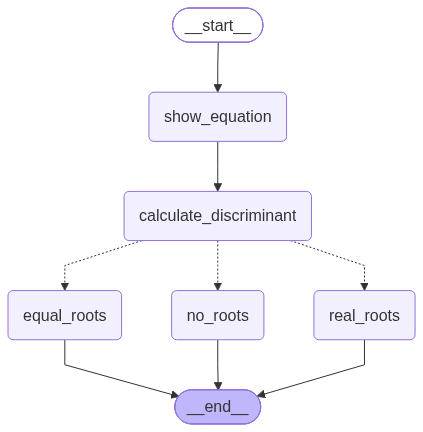

In [24]:
workflow

In [29]:
intial_state={
    'a':1,
    'b':-2,
    'c':9
}
workflow.invoke(intial_state)

{'a': 1,
 'b': -2,
 'c': 9,
 'equation': '1x² + -2x + 9',
 'discriminant': -32,
 'result': 'No real roots exist'}